Saving 스크린샷 2026-09-28 152652.png to 스크린샷 2026-09-28 152652.png


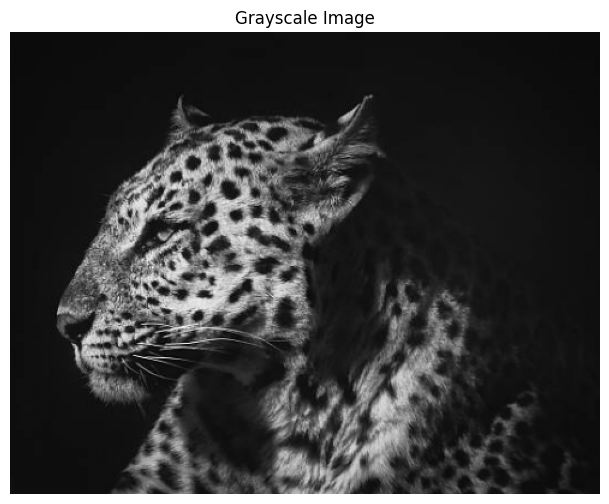

Image shape: (385, 491)


In [ ]:
from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()
filename = next(iter(uploaded))

# 이미지 읽기
img = cv2.imread(filename)

# Grayscale 변환
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(8, 6))
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")
plt.show()

print("Image shape:", gray.shape)

Otsu Threshold: 77.0


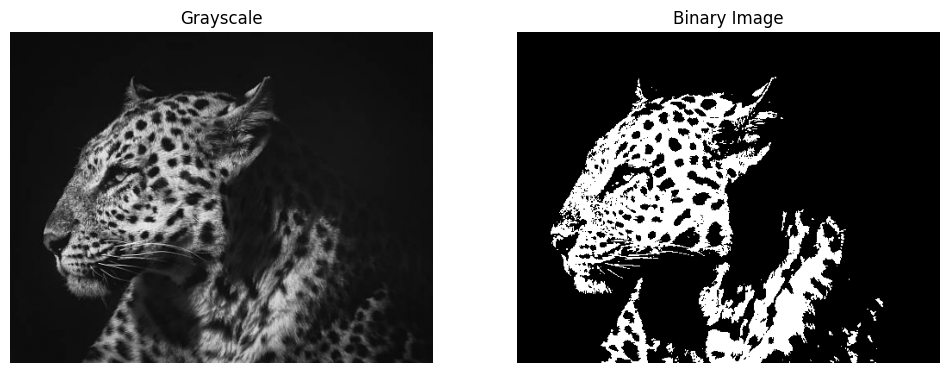

In [ ]:
# Otsu Thresholding
threshold, binary = cv2.threshold(
    gray,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

print("Otsu Threshold:", threshold)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary, cmap="gray")
plt.title("Binary Image")
plt.axis("off")

plt.show()

In [ ]:
# ============================================================
# Structuring Elements
# ============================================================

# Vertical 5x1
vertical_SE = np.ones((5, 1), dtype=np.uint8)

# Horizontal 1x5
horizontal_SE = np.ones((1, 5), dtype=np.uint8)

# Square 5x5
square_SE = np.ones((5, 5), dtype=np.uint8)

# Diamond 5x5
diamond_SE = np.array([
    [0, 0, 1, 0, 0],
    [0, 1, 1, 1, 0],
    [1, 1, 1, 1, 1],
    [0, 1, 1, 1, 0],
    [0, 0, 1, 0, 0]
], dtype=np.uint8)

SEs = {
    "Vertical": vertical_SE,
    "Horizontal": horizontal_SE,
    "Square": square_SE,
    "Diamond": diamond_SE
}

for name, se in SEs.items():
    print(f"\n{name} SE")
    print(se)


Vertical SE
[[1]
 [1]
 [1]
 [1]
 [1]]

Horizontal SE
[[1 1 1 1 1]]

Square SE
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]

Diamond SE
[[0 0 1 0 0]
 [0 1 1 1 0]
 [1 1 1 1 1]
 [0 1 1 1 0]
 [0 0 1 0 0]]


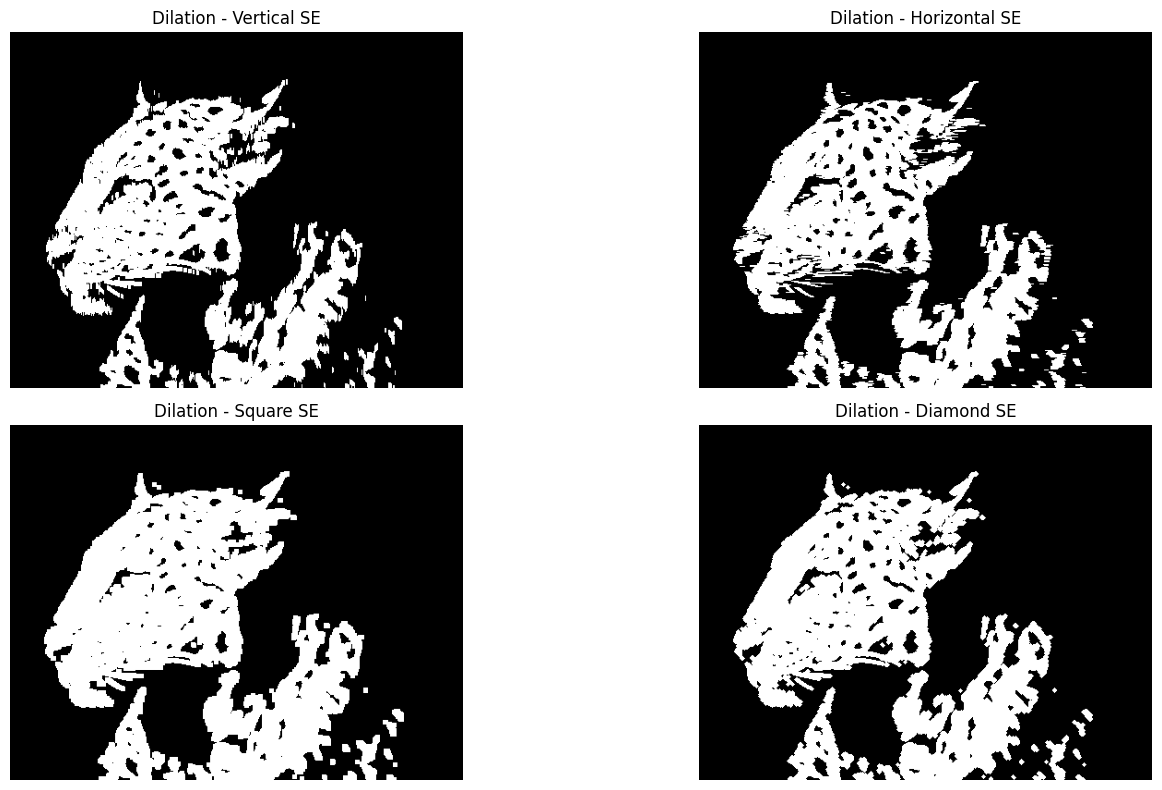

In [ ]:
# ============================================================
# Dilation with 4 Structuring Elements
# ============================================================

dilation_results = {}

plt.figure(figsize=(16, 8))

for i, (name, se) in enumerate(SEs.items()):

    result = cv2.dilate(
        binary,
        se,
        iterations=1
    )

    dilation_results[name] = result

    plt.subplot(2, 2, i + 1)
    plt.imshow(result, cmap="gray")
    plt.title(f"Dilation - {name} SE")
    plt.axis("off")

plt.tight_layout()
plt.show()

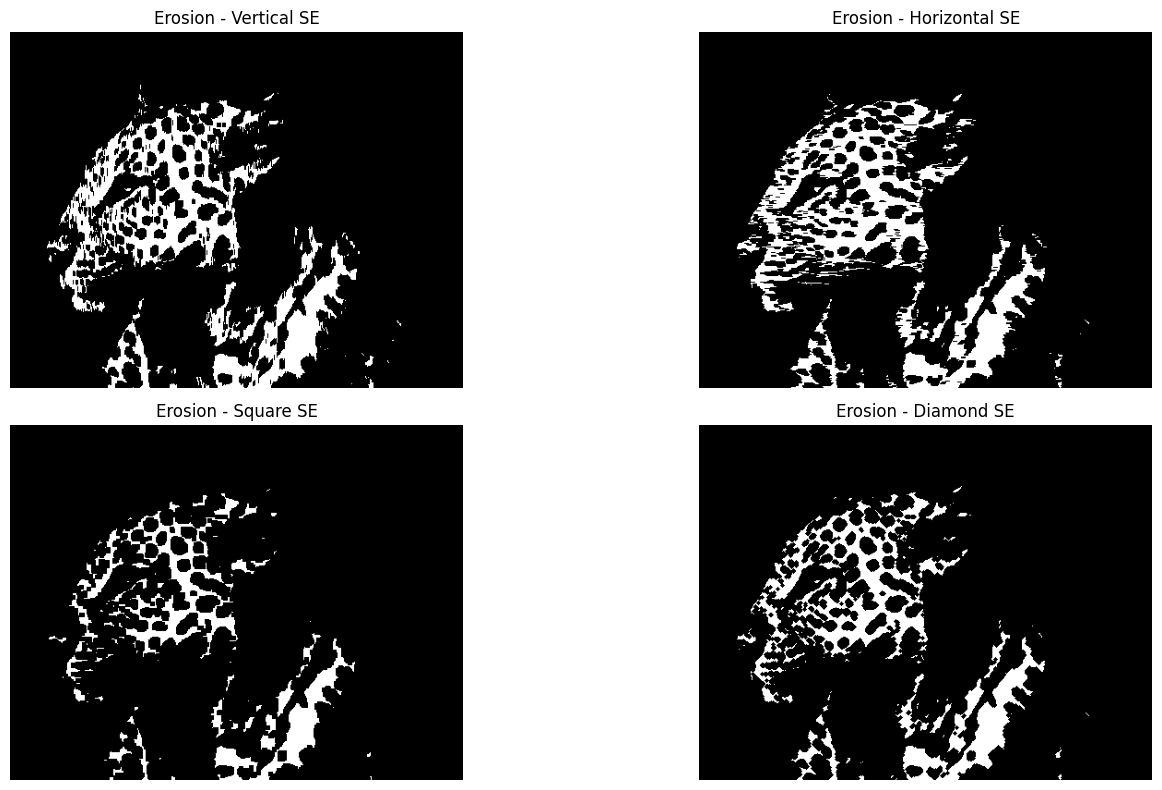

In [ ]:
# ============================================================
# Erosion with 4 Structuring Elements
# ============================================================

erosion_results = {}

plt.figure(figsize=(16, 8))

for i, (name, se) in enumerate(SEs.items()):

    result = cv2.erode(
        binary,
        se,
        iterations=1
    )

    erosion_results[name] = result

    plt.subplot(2, 2, i + 1)
    plt.imshow(result, cmap="gray")
    plt.title(f"Erosion - {name} SE")
    plt.axis("off")

plt.tight_layout()
plt.show()

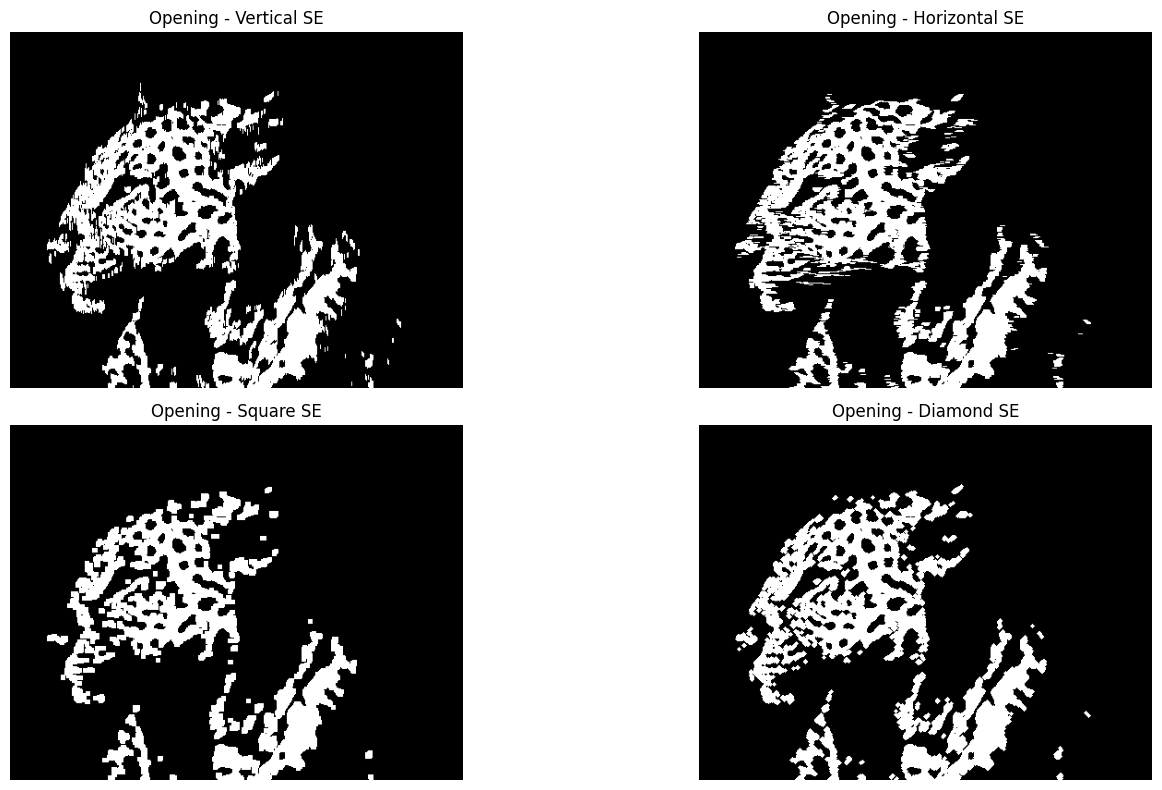

In [ ]:
# ============================================================
# Opening with 4 Structuring Elements
# Erosion -> Dilation
# ============================================================

opening_results = {}

plt.figure(figsize=(16, 8))

for i, (name, se) in enumerate(SEs.items()):

    # Step 1: Erosion
    eroded = cv2.erode(
        binary,
        se,
        iterations=1
    )

    # Step 2: Dilation
    opened = cv2.dilate(
        eroded,
        se,
        iterations=1
    )

    opening_results[name] = opened

    plt.subplot(2, 2, i + 1)
    plt.imshow(opened, cmap="gray")
    plt.title(f"Opening - {name} SE")
    plt.axis("off")

plt.tight_layout()
plt.show()

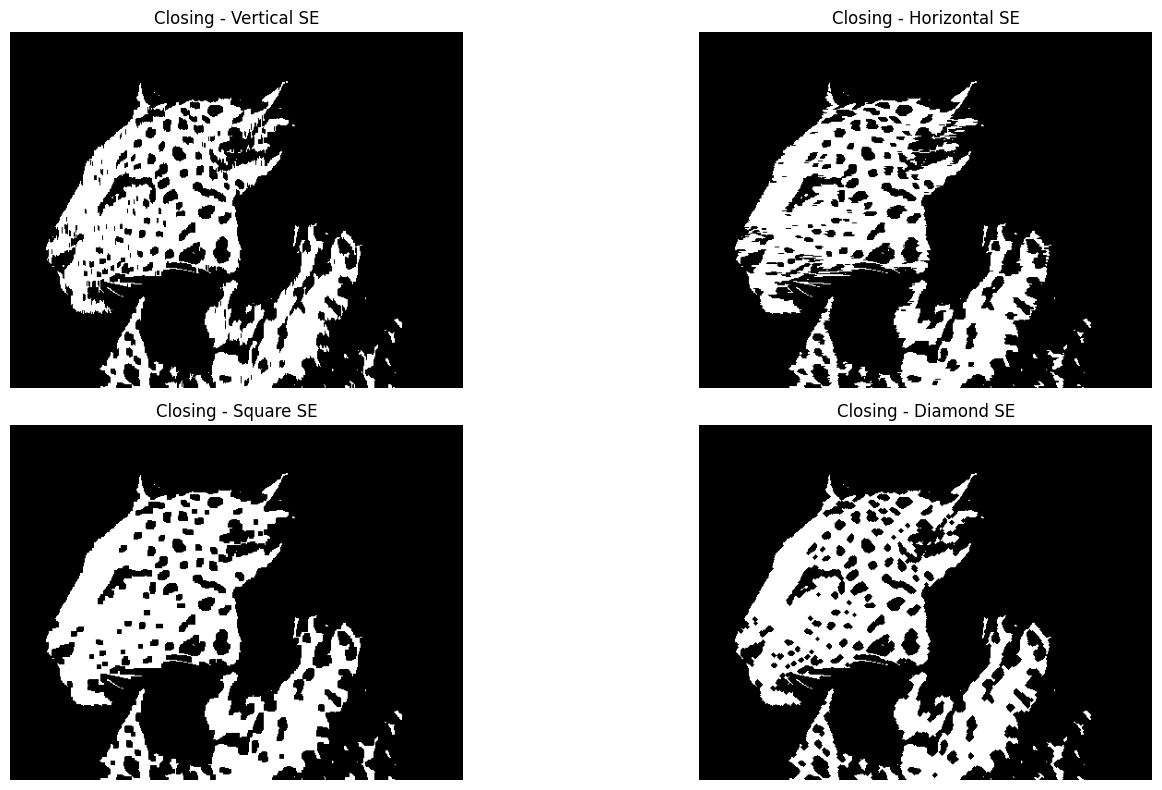

In [ ]:
# ============================================================
# Closing with 4 Structuring Elements
# Dilation -> Erosion
# ============================================================

closing_results = {}

plt.figure(figsize=(16, 8))

for i, (name, se) in enumerate(SEs.items()):

    # Step 1: Dilation
    dilated = cv2.dilate(
        binary,
        se,
        iterations=1
    )

    # Step 2: Erosion
    closed = cv2.erode(
        dilated,
        se,
        iterations=1
    )

    closing_results[name] = closed

    plt.subplot(2, 2, i + 1)
    plt.imshow(closed, cmap="gray")
    plt.title(f"Closing - {name} SE")
    plt.axis("off")

plt.tight_layout()
plt.show()

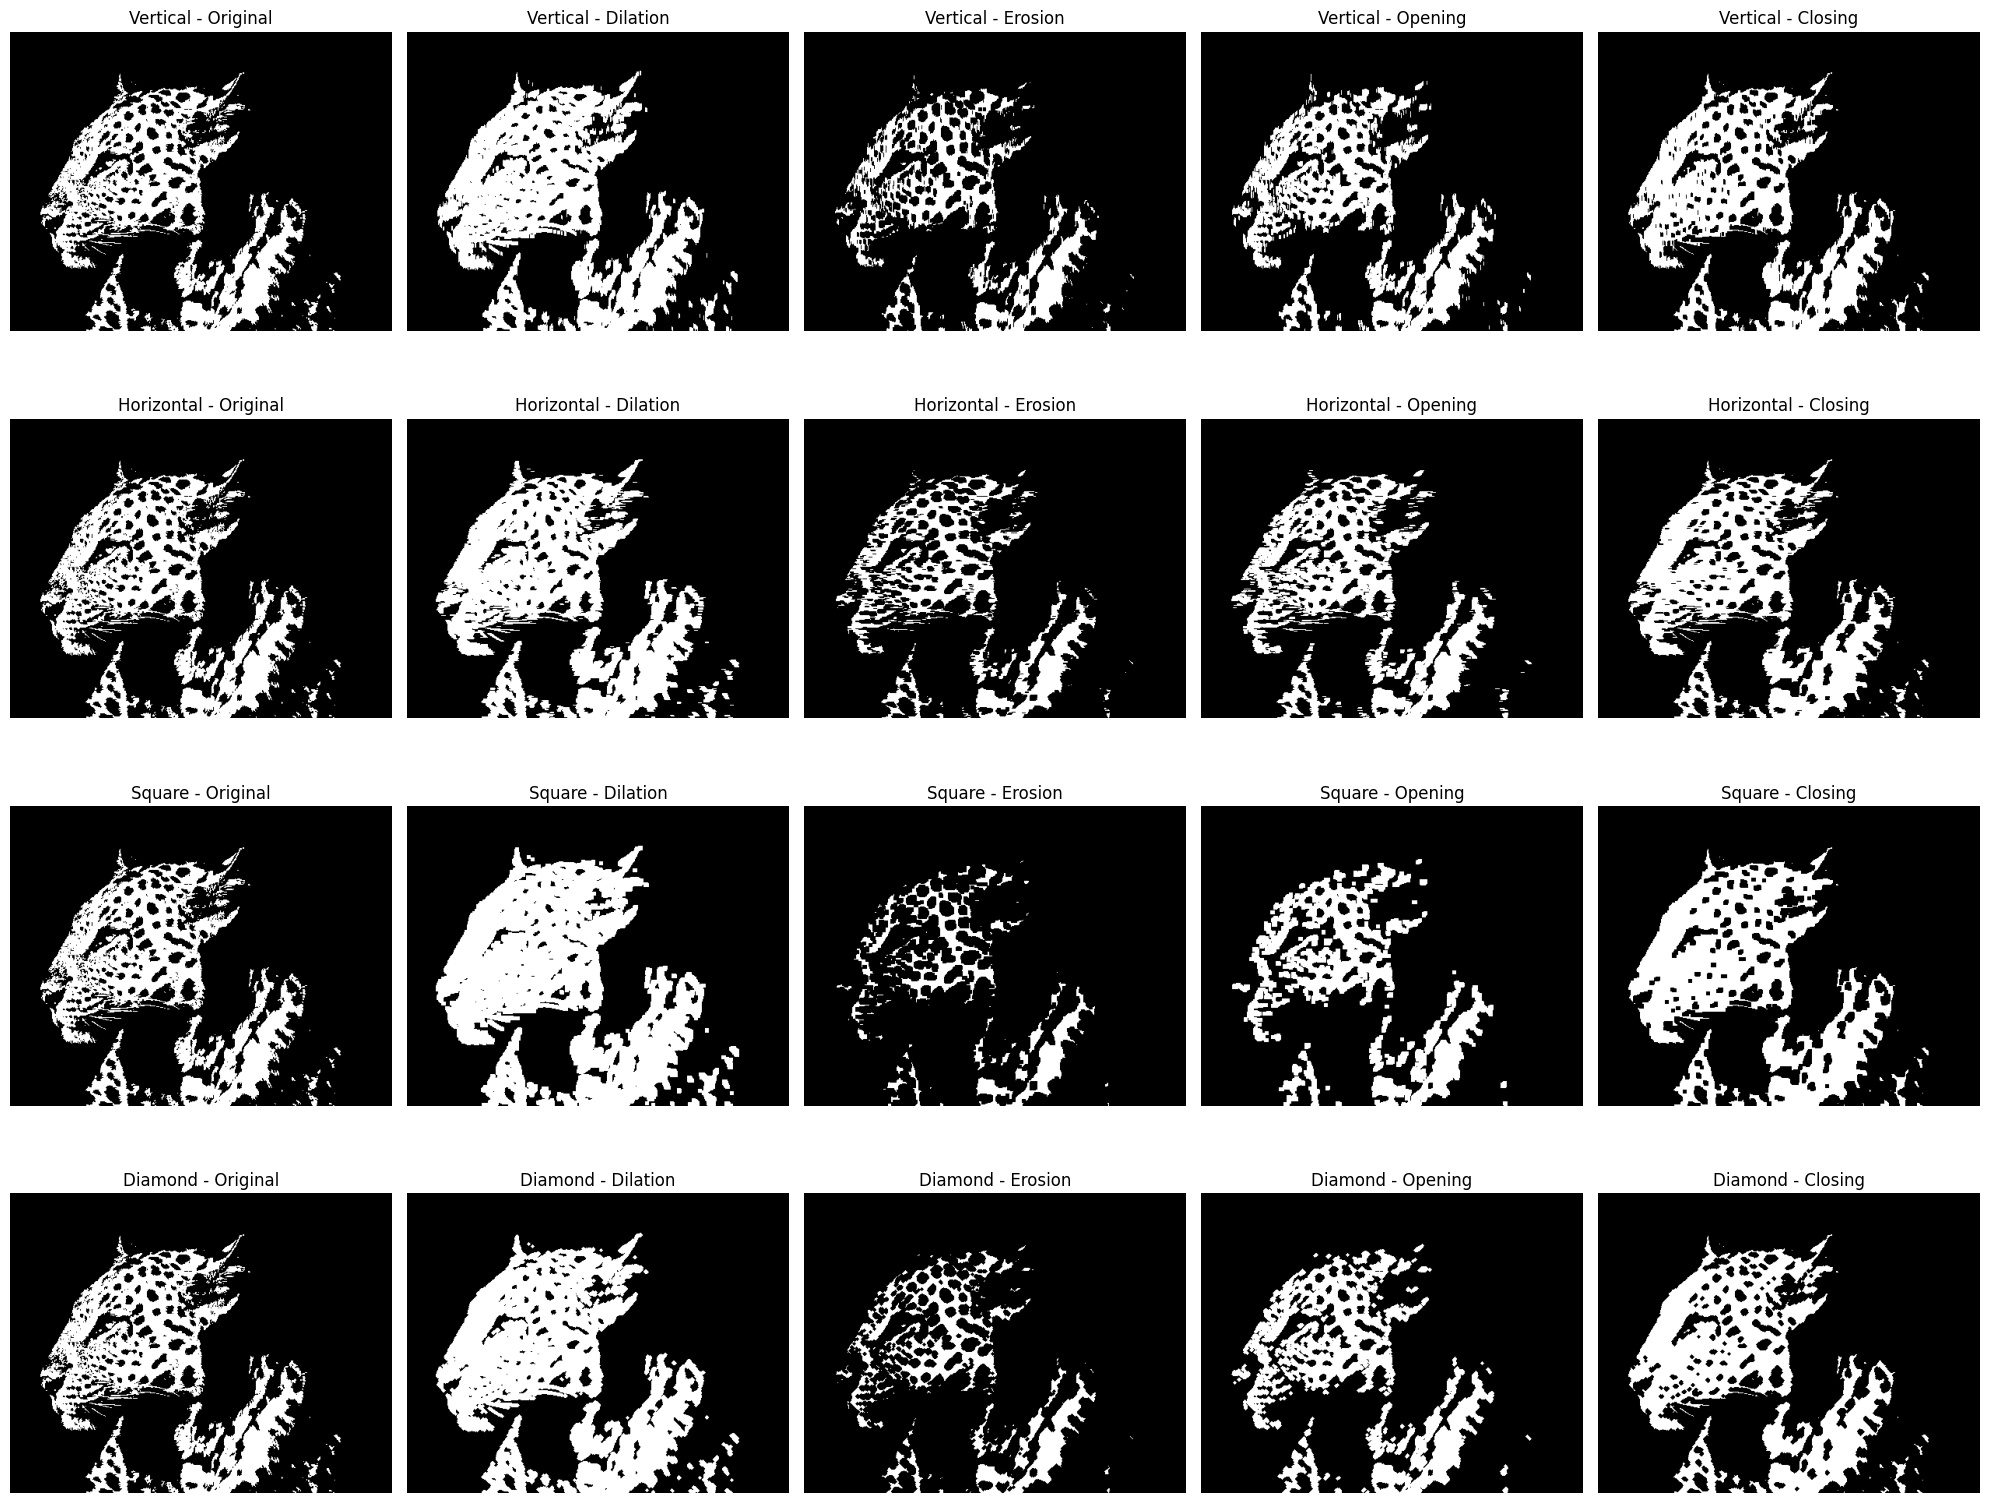

In [ ]:
# ============================================================
# Final Comparison
# Row    : SE type
# Column : Original / Dilation / Erosion / Opening / Closing
# ============================================================

names = list(SEs.keys())

plt.figure(figsize=(20, 16))

for row, name in enumerate(names):

    images = [
        binary,
        dilation_results[name],
        erosion_results[name],
        opening_results[name],
        closing_results[name]
    ]

    titles = [
        f"{name} - Original",
        f"{name} - Dilation",
        f"{name} - Erosion",
        f"{name} - Opening",
        f"{name} - Closing"
    ]

    for col in range(5):

        plt.subplot(4, 5, row * 5 + col + 1)
        plt.imshow(images[col], cmap="gray")
        plt.title(titles[col])
        plt.axis("off")

plt.tight_layout()
plt.show()